# ARTI 403 - Floating Waste Detection in Water
## Person 2: Colour Analysis, Colour Thresholding and Edge Detection

**Task:** analyse the images in RGB / HSV / Lab, test colour thresholding to separate floating waste from water,
apply Sobel and Canny edge detection, compare several settings and pick the best ones.



In [7]:
import json
import inspect
import shutil
import warnings
from pathlib import Path
import os

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

## 0. Configuration

In [8]:
import os

DATA_DIR = None                 # None = auto-detect the rft_prepared folder next to the notebook
SPLIT = "val"                   # tune on validation only (never on test)
MAX_IMAGES = 150                # number of images used for the experiments
SEED = 42

PAD_VALUE = 114                 # letterbox padding colour used by Person 1
PAD_TOL = 4                     # tolerance because of JPEG compression
PIX_PER_IMAGE = 3000            # pixels sampled per class and image for the colour analysis
N_VIS = 6                       # images shown in the visual comparison


def notebook_dir():
    f = globals().get("__vsc_ipynb_file__")        # VS Code gives the notebook's own path
    return Path(f).resolve().parent if f else Path.cwd()


NB_DIR = notebook_dir()
OUT_DIR = NB_DIR / "person2_output"                # always created next to the notebook
for sub in ("visuals", "color_masks", "sobel_edges", "canny_edges"):
    (OUT_DIR / sub).mkdir(parents=True, exist_ok=True)

rng

Generator(PCG64) at 0x2C9C8A4D7E0

## 1. Load images and labels, remove the padding

In [9]:
def find_data():
    env = os.environ.get("RFT_DATA_DIR")                      # optional: set this variable to skip the search
    if env and (Path(env) / "images").is_dir():
        return Path(env)
    bases = []
    for b in (NB_DIR, Path.cwd()):                            # start from the notebook folder, then the working folder
        for x in [b, *list(b.parents)[:3]]:
            if x not in bases:
                bases.append(x)
    for base in bases:
        cands = [base / "rft_prepared", *sorted(base.glob("*/rft_prepared")), *sorted(base.glob("*/*/rft_prepared"))]
        for cand in cands:
            for c in (cand, cand / "rft_prepared"):          # also accept a doubled folder rft_prepared/rft_prepared
                if (c / "images").is_dir():
                    return c
    return None


if DATA_DIR is None:
    DATA_DIR = find_data()
if DATA_DIR is None:                                          # last resort: ask once, so nobody has to edit the code
    typed = input("rft_prepared was not found automatically. Paste its full path here: ").strip().strip('"')
    DATA_DIR = typed or None
if DATA_DIR is None or not (Path(DATA_DIR) / "images").is_dir():
    raise FileNotFoundError(f"rft_prepared/ not found (looked from {NB_DIR} and {Path.cwd()}). "
                            "Set DATA_DIR in the configuration cell to a folder that contains images/ and labels/.")
DATA_DIR = Path(DATA_DIR)
print("Data folder:", DATA_DIR.resolve())
print("Outputs go to:", OUT_DIR.resolve())


def cv_read(path):
    data = np.fromfile(str(path), dtype=np.uint8)           # unicode-safe on Windows
    return cv2.imdecode(data, cv2.IMREAD_COLOR) if data.size else None


def cv_write(path, img):
    ok, buf = cv2.imencode(Path(path).suffix or ".png", img)
    if not ok:
        raise IOError(f"Could not encode {path}")
    buf.tofile(str(path))


def content_bbox(img):
    # bounding box of the real image inside the grey letterbox padding
    pad = np.all(np.abs(img.astype(np.int16) - PAD_VALUE) <= PAD_TOL, axis=2)
    rows = np.where(pad.mean(axis=1) < 0.98)[0]
    cols = np.where(pad.mean(axis=0) < 0.98)[0]
    if len(rows) == 0 or len(cols) == 0:
        return 0, 0, img.shape[1], img.shape[0]
    return int(cols[0]), int(rows[0]), int(cols[-1]) + 1, int(rows[-1]) + 1


def make_valid(img):
    # valid = real image pixels; inner = valid shrunk by a few pixels so the padding border is never counted as an edge
    h, w = img.shape[:2]
    x0, y0, x1, y1 = content_bbox(img)
    valid = np.zeros((h, w), bool)
    valid[y0:y1, x0:x1] = True
    inner = cv2.erode(valid.astype(np.uint8), np.ones((17, 17), np.uint8)) > 0
    return valid, inner


def read_boxes(label_path, w, h):
    boxes = []
    if label_path.exists():
        for line in label_path.read_text().splitlines():
            t = line.split()
            if len(t) < 5:
                continue
            cx, cy, bw, bh = [float(v) for v in t[1:5]]
            x0, y0 = int(round((cx - bw / 2) * w)), int(round((cy - bh / 2) * h))
            x1, y1 = int(round((cx + bw / 2) * w)), int(round((cy + bh / 2) * h))
            x0, y0, x1, y1 = max(x0, 0), max(y0, 0), min(x1, w), min(y1, h)
            if x1 > x0 and y1 > y0:
                boxes.append((x0, y0, x1, y1))
    return boxes


img_dir, lbl_dir = DATA_DIR / "images" / SPLIT, DATA_DIR / "labels" / SPLIT
files = sorted(p for p in img_dir.glob("*.jpg") if "_aug" not in p.stem)     # originals only
if not files:
    raise RuntimeError(f"No images in {img_dir}")
if len(files) > MAX_IMAGES:
    files = [files[i] for i in sorted(rng.choice(len(files), MAX_IMAGES, replace=False))]

samples = []
for p in files:
    img = cv_read(p)
    if img is None:
        continue
    h, w = img.shape[:2]
    valid, inner = make_valid(img)
    boxes = read_boxes(lbl_dir / (p.stem + ".txt"), w, h)
    gt = np.zeros((h, w), bool)
    for x0, y0, x1, y1 in boxes:
        gt[y0:y1, x0:x1] = True
    gt &= valid
    samples.append(dict(name=p.name, img=img, valid=valid, inner=inner, boxes=boxes, gt=gt))

n_boxes = sum(len(s["boxes"]) for s in samples)
print(f"Split: {SPLIT} | images used: {len(samples)} | boxes: {n_boxes}")
print(f"Real-image area (without padding): {np.mean([s['valid'].mean() for s in samples]):.1%} of each 640x640 image")
print(f"Waste (box) area: {np.mean([s['gt'].sum() / max(s['valid'].sum(), 1) for s in samples]):.2%} of the real image area")

Data folder: C:\Users\xmoha\OneDrive\سطح المكتب\Image_Project\Image_Processing_UNI_Project\rft_prepared
Outputs go to: D:\person2_output
Split: val | images used: 150 | boxes: 214
Real-image area (without padding): 100.0% of each 640x640 image
Waste (box) area: 6.03% of the real image area


## 2. Colour-space analysis (RGB, HSV, Lab)


Images used for the colour analysis: 150 | waste pixels: 440608 | water pixels: 450000
channel space  d_prime_raw  overlap_raw  d_prime_centred  overlap_centred
      V   HSV        0.079        0.898            0.084            0.870
      B   RGB        0.070        0.926            0.076            0.894
      G   RGB        0.055        0.902            0.060            0.864
      L   Lab        0.050        0.905            0.055            0.871
      R   RGB        0.041        0.897            0.044            0.864
      b   Lab        0.034        0.899            0.040            0.828
      H   HSV        0.152        0.874            0.027            0.817
      a   Lab        0.019        0.855            0.021            0.787
      S   HSV        0.024        0.924            0.017            0.873

Most separable channel per colour space (centred): {'HSV': 'V', 'Lab': 'L', 'RGB': 'B'}


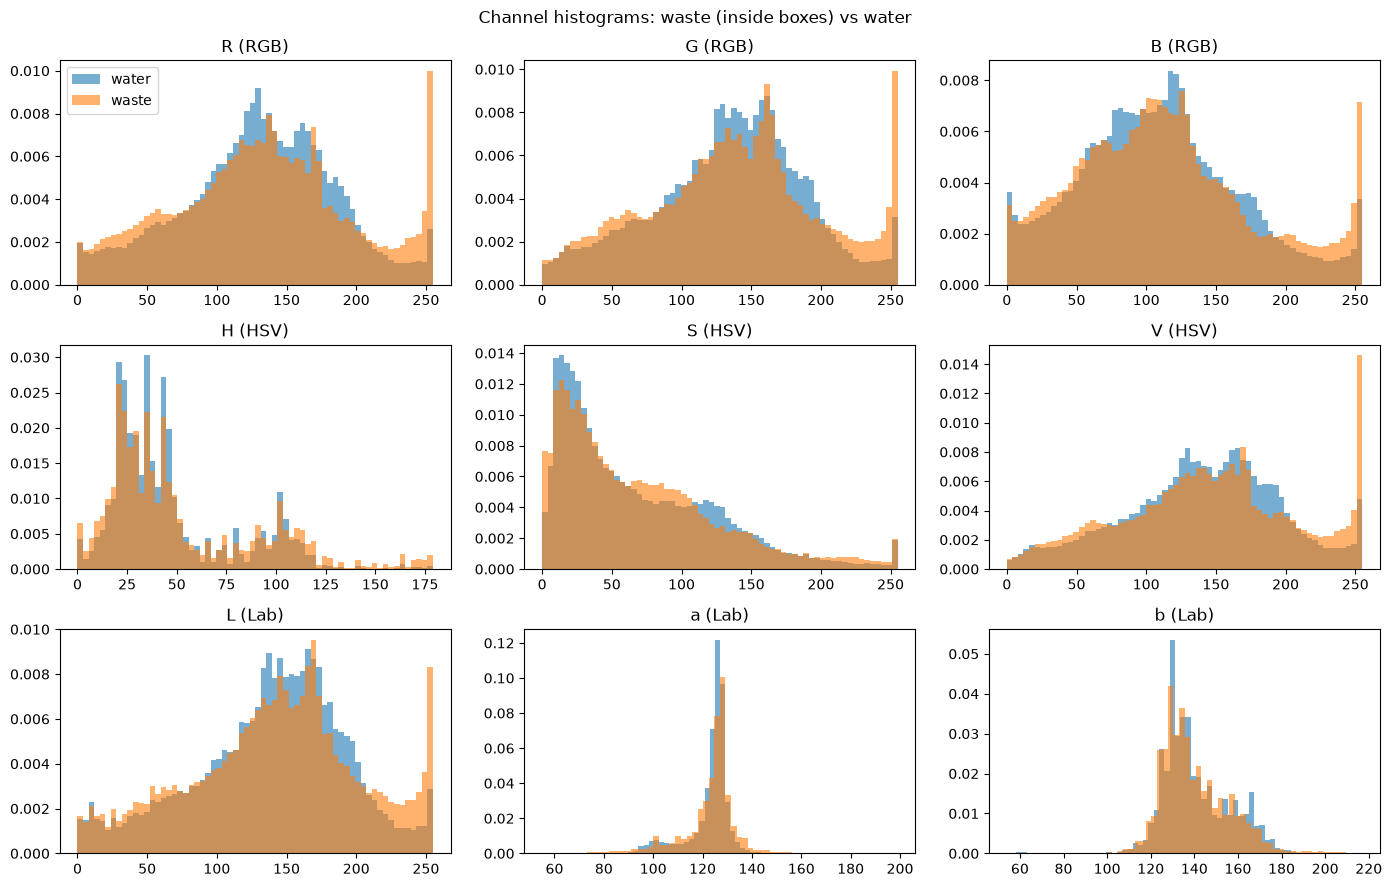

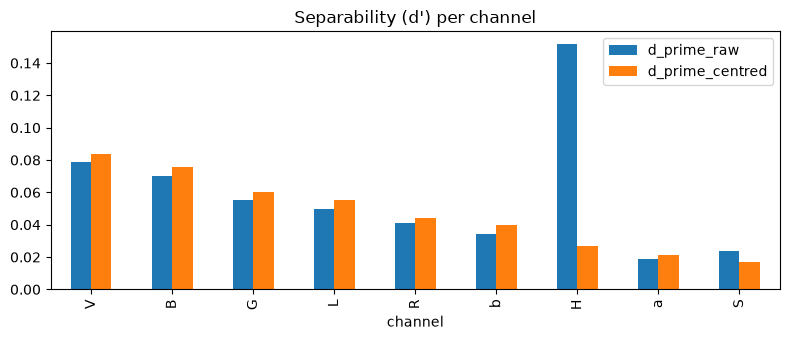

In [10]:
CHANNELS = ["R", "G", "B", "H", "S", "V", "L", "a", "b"]
SPACE_OF = dict(R="RGB", G="RGB", B="RGB", H="HSV", S="HSV", V="HSV", L="Lab", a="Lab", b="Lab")


def channel_stack(img):
    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    return np.dstack([rgb, hsv, lab]).astype(np.float32)          # H x W x 9


waste_raw, water_raw, waste_c, water_c = [], [], [], []
used = 0
for s in samples:
    wa, wt = s["gt"], s["valid"] & ~s["gt"]
    if wa.sum() < 50 or wt.sum() < 50:
        continue
    st = channel_stack(s["img"])
    a, b = st[wa], st[wt]
    ref = b[rng.choice(len(b), min(len(b), 20000), replace=False)]
    med = np.median(ref, axis=0)
    a = a[rng.choice(len(a), min(len(a), PIX_PER_IMAGE), replace=False)]
    b = b[rng.choice(len(b), min(len(b), PIX_PER_IMAGE), replace=False)]
    ca, cb = a - med, b - med
    for c in (ca, cb):
        c[:, 3] = (c[:, 3] + 90) % 180 - 90                       # hue is circular
    waste_raw.append(a); water_raw.append(b); waste_c.append(ca); water_c.append(cb)
    used += 1

waste_raw, water_raw = np.vstack(waste_raw), np.vstack(water_raw)
waste_c, water_c = np.vstack(waste_c), np.vstack(water_c)
print(f"Images used for the colour analysis: {used} | waste pixels: {len(waste_raw)} | water pixels: {len(water_raw)}")


def dprime(a, b):
    return np.abs(a.mean(0) - b.mean(0)) / np.sqrt((a.var(0) + b.var(0)) / 2 + 1e-9)


def overlap(a, b, bins=64):
    out = []
    for j in range(a.shape[1]):
        lo, hi = min(a[:, j].min(), b[:, j].min()), max(a[:, j].max(), b[:, j].max())
        ha, _ = np.histogram(a[:, j], bins=bins, range=(lo, hi))
        hb, _ = np.histogram(b[:, j], bins=bins, range=(lo, hi))
        out.append(np.minimum(ha / ha.sum(), hb / hb.sum()).sum())
    return np.array(out)


color_table = pd.DataFrame({
    "channel": CHANNELS,
    "space": [SPACE_OF[c] for c in CHANNELS],
    "d_prime_raw": dprime(waste_raw, water_raw),
    "overlap_raw": overlap(waste_raw, water_raw),
    "d_prime_centred": dprime(waste_c, water_c),
    "overlap_centred": overlap(waste_c, water_c),
}).round(3).sort_values("d_prime_centred", ascending=False).reset_index(drop=True)
color_table.to_csv(OUT_DIR / "01_colour_space_separability.csv", index=False)
print(color_table.to_string(index=False))

best_by_space = color_table.loc[color_table.groupby("space")["d_prime_centred"].idxmax()].set_index("space")["channel"]
print("\nMost separable channel per colour space (centred):", best_by_space.to_dict())

fig, axes = plt.subplots(3, 3, figsize=(14, 9))
for j, (ax, ch) in enumerate(zip(axes.ravel(), CHANNELS)):
    ax.hist(water_raw[:, j], bins=64, alpha=0.6, density=True, label="water")
    ax.hist(waste_raw[:, j], bins=64, alpha=0.6, density=True, label="waste")
    ax.set_title(f"{ch} ({SPACE_OF[ch]})")
    if j == 0:
        ax.legend()
plt.suptitle("Channel histograms: waste (inside boxes) vs water")
plt.tight_layout()
plt.savefig(OUT_DIR / "01_channel_histograms.png", dpi=120)
plt.show()

fig, ax = plt.subplots(figsize=(8, 3.5))
color_table.set_index("channel")[["d_prime_raw", "d_prime_centred"]].plot.bar(ax=ax, title="Separability (d') per channel")
plt.tight_layout()
plt.savefig(OUT_DIR / "01_dprime_per_channel.png", dpi=120)
plt.show()

## 3. Colour thresholding and edge detection: the functions


In [11]:
def water_ref(arr, valid, n=20000):
    # water colour of an image = median colour of its real pixels (water is the majority)
    v = arr[valid]
    if len(v) > n:
        v = v[np.random.default_rng(0).choice(len(v), n, replace=False)]
    return np.median(v, axis=0)


def prep(img, blur, valid):
    im = cv2.GaussianBlur(img, (blur, blur), 0) if blur else img
    hsv = cv2.cvtColor(im, cv2.COLOR_BGR2HSV)
    lab = cv2.cvtColor(im, cv2.COLOR_BGR2LAB)
    P = dict(gray=cv2.cvtColor(im, cv2.COLOR_BGR2GRAY), S=hsv[..., 1], V=hsv[..., 2],
             L=lab[..., 0], a=lab[..., 1], b=lab[..., 2],
             RGB=im.astype(np.float32), HSV=hsv.astype(np.float32), Lab=lab.astype(np.float32))
    for k in ("RGB", "HSV", "Lab"):
        P[k + "_ref"] = water_ref(P[k], valid)
    return P


def dist_map(P, kind):
    d = P[kind] - P[kind + "_ref"]
    if kind == "HSV":
        dh = np.abs(d[..., 0])
        dh = np.minimum(dh, 180 - dh) * 2.0                         # circular hue, scaled to the 0-255 range
        return np.sqrt(dh ** 2 + d[..., 1] ** 2 + d[..., 2] ** 2)
    return np.sqrt((d ** 2).sum(-1))


def robust_thr(dm, valid, k):
    v = dm[valid]
    m = np.median(v)
    mad = np.median(np.abs(v - m)) * 1.4826
    return m + k * max(mad, 1.0)


def otsu_minority(ch, valid):
    vals = ch[valid].reshape(-1, 1)
    if len(vals) == 0:
        return np.zeros(ch.shape, bool)
    t, _ = cv2.threshold(vals, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    hi = ch > t
    return hi if hi[valid].mean() <= 0.5 else ~hi


def color_pred(cfg, P, valid):
    if cfg["method"] == "otsu":
        m = otsu_minority(P[cfg["channel"]], valid)
    else:
        dm = dist_map(P, cfg["channel"])
        m = dm > robust_thr(dm, valid, cfg["k"])
    return m & valid


def edge_pred(cfg, P, inner):
    ch = P[cfg["channel"]]
    if inner.sum() == 0:
        return np.zeros(ch.shape, bool)
    if cfg["method"] == "canny":
        e = cv2.Canny(ch, cfg["lo"], cfg["hi"], L2gradient=True) > 0
    else:
        gx = cv2.Sobel(ch, cv2.CV_32F, 1, 0, ksize=cfg["ksize"])
        gy = cv2.Sobel(ch, cv2.CV_32F, 0, 1, ksize=cfg["ksize"])
        mag = cv2.magnitude(gx, gy)
        v = mag[inner]
        e = mag > (v.mean() + cfg["t"] * v.std())
    return e & inner


def color_name(c):
    return f"{c['method']}_{c['channel']}" + (f"_k{c['k']}" if c["k"] is not None else "") + f"_blur{c['blur']}"


def edge_name(c):
    if c["method"] == "canny":
        return f"canny_{c['channel']}_{c['lo']}-{c['hi']}_blur{c['blur']}"
    return f"sobel_{c['channel']}_ks{c['ksize']}_t{c['t']}_blur{c['blur']}"


COLOR_CONFIGS = []
for blur in (0, 5, 9):
    for ch in ("gray", "S", "V", "L", "a", "b"):
        COLOR_CONFIGS.append(dict(method="otsu", channel=ch, k=None, blur=blur))
    for sp in ("RGB", "HSV", "Lab"):
        for k in (3, 5, 8):
            COLOR_CONFIGS.append(dict(method="dist", channel=sp, k=k, blur=blur))

EDGE_CONFIGS = []
for ch in ("gray", "S"):
    for blur in (0, 5, 9):
        for ks in (3, 5):
            for t in (2, 3, 4, 5, 6):
                EDGE_CONFIGS.append(dict(method="sobel", channel=ch, blur=blur, ksize=ks, t=t))
        for lo, hi in ((30, 90), (50, 150), (80, 200), (100, 250), (150, 300)):
            EDGE_CONFIGS.append(dict(method="canny", channel=ch, blur=blur, lo=lo, hi=hi))

print(len(COLOR_CONFIGS), "colour settings and", len(EDGE_CONFIGS), "edge settings will be compared on", len(samples), "images")

45 colour settings and 90 edge settings will be compared on 150 images


## 4. Run all settings on the validation images


In [12]:
def new_color_acc():
    return dict(tp=0, fp=0, fn=0, hit=0, nb=0, pred=0, pix=0, ious=[])


def new_edge_acc():
    return dict(n_edge=0, n_in_dil=0, hit=0, nb=0, e_in=0, e_out=0, a_in=0, a_out=0)


color_acc = {color_name(c): new_color_acc() for c in COLOR_CONFIGS}
edge_acc = {edge_name(c): new_edge_acc() for c in EDGE_CONFIGS}

for i, s in enumerate(samples):
    valid, inner, gt, boxes = s["valid"], s["inner"], s["gt"], s["boxes"]
    gt_dil = cv2.dilate(gt.astype(np.uint8), np.ones((7, 7), np.uint8)) > 0
    Ps = {b: prep(s["img"], b, valid) for b in (0, 5, 9)}

    for cfg in COLOR_CONFIGS:
        pred = color_pred(cfg, Ps[cfg["blur"]], valid)
        a = color_acc[color_name(cfg)]
        tp = int((pred & gt).sum()); fp = int((pred & ~gt).sum()); fn = int((~pred & gt).sum())
        a["tp"] += tp; a["fp"] += fp; a["fn"] += fn
        a["pred"] += int(pred.sum()); a["pix"] += int(valid.sum())
        for x0, y0, x1, y1 in boxes:
            a["nb"] += 1
            if pred[y0:y1, x0:x1].mean() >= 0.2:
                a["hit"] += 1
        a["ious"].append(tp / (tp + fp + fn) if (tp + fp + fn) > 0 and gt.any() else np.nan)

    for cfg in EDGE_CONFIGS:
        e = edge_pred(cfg, Ps[cfg["blur"]], inner)
        a = edge_acc[edge_name(cfg)]
        a["n_edge"] += int(e.sum()); a["n_in_dil"] += int((e & gt_dil).sum())
        a["e_in"] += int((e & gt).sum()); a["a_in"] += int(gt.sum())
        a["e_out"] += int((e & ~gt).sum()); a["a_out"] += int((inner & ~gt).sum())
        for x0, y0, x1, y1 in boxes:
            a["nb"] += 1
            if e[max(y0 - 3, 0):y1 + 3, max(x0 - 3, 0):x1 + 3].sum() >= 5:
                a["hit"] += 1

    if (i + 1) % 25 == 0 or i + 1 == len(samples):
        print(f"  processed {i + 1}/{len(samples)} images")

rows = []
for c in COLOR_CONFIGS:
    a = color_acc[color_name(c)]
    prec = a["tp"] / max(a["tp"] + a["fp"], 1)
    rec = a["tp"] / max(a["tp"] + a["fn"], 1)
    rows.append(dict(setting=color_name(c), method=c["method"], channel=c["channel"], k=c["k"], blur=c["blur"],
                     precision=prec, recall=rec, f1=2 * prec * rec / max(prec + rec, 1e-9),
                     iou=a["tp"] / max(a["tp"] + a["fp"] + a["fn"], 1),
                     box_recall=a["hit"] / max(a["nb"], 1), mask_share=a["pred"] / max(a["pix"], 1)))
color_res = pd.DataFrame(rows).round(4).sort_values("iou", ascending=False).reset_index(drop=True)

rows = []
for c in EDGE_CONFIGS:
    a = edge_acc[edge_name(c)]
    prec = a["n_in_dil"] / max(a["n_edge"], 1)
    rec = a["hit"] / max(a["nb"], 1)
    dens_in = a["e_in"] / max(a["a_in"], 1)
    dens_out = a["e_out"] / max(a["a_out"], 1)
    rows.append(dict(setting=edge_name(c), method=c["method"], channel=c["channel"], blur=c["blur"],
                     ksize=c.get("ksize"), t=c.get("t"), lo=c.get("lo"), hi=c.get("hi"),
                     edge_precision=prec, box_recall=rec, f1=2 * prec * rec / max(prec + rec, 1e-9),
                     density_ratio=dens_in / max(dens_out, 1e-9), edge_share=a["n_edge"] / max(sum(s["inner"].sum() for s in samples), 1)))
edge_res = pd.DataFrame(rows).round(4).sort_values("f1", ascending=False).reset_index(drop=True)

color_res.to_csv(OUT_DIR / "02_colour_threshold_results.csv", index=False)
edge_res.to_csv(OUT_DIR / "03_edge_detection_results.csv", index=False)

  processed 25/150 images
  processed 50/150 images
  processed 75/150 images
  processed 100/150 images
  processed 125/150 images
  processed 150/150 images


## 5. Comparison of the settings

=== Colour thresholding (top 10 by IoU) ===
          setting  precision  recall     f1    iou  box_recall  mask_share
dist_Lab_k3_blur0     0.2025  0.2303 0.2155 0.1208      0.3645      0.0686
dist_Lab_k3_blur5     0.2025  0.2290 0.2150 0.1204      0.3785      0.0682
dist_Lab_k3_blur9     0.2008  0.2251 0.2123 0.1187      0.3598      0.0676
dist_RGB_k3_blur0     0.1978  0.2168 0.2069 0.1154      0.3645      0.0661
dist_RGB_k3_blur5     0.1955  0.2129 0.2038 0.1135      0.3598      0.0657
dist_RGB_k3_blur9     0.1944  0.2112 0.2025 0.1126      0.3551      0.0655
dist_HSV_k3_blur9     0.1678  0.1895 0.1780 0.0977      0.3738      0.0681
dist_HSV_k3_blur5     0.1686  0.1877 0.1777 0.0975      0.3738      0.0671
dist_HSV_k3_blur0     0.1662  0.1830 0.1742 0.0954      0.3692      0.0664
dist_RGB_k5_blur0     0.2949  0.1223 0.1728 0.0946      0.1355      0.0250

=== Sobel (top 5 by F1) ===
             setting  edge_precision  box_recall     f1  density_ratio
sobel_S_ks5_t6_blur9          0

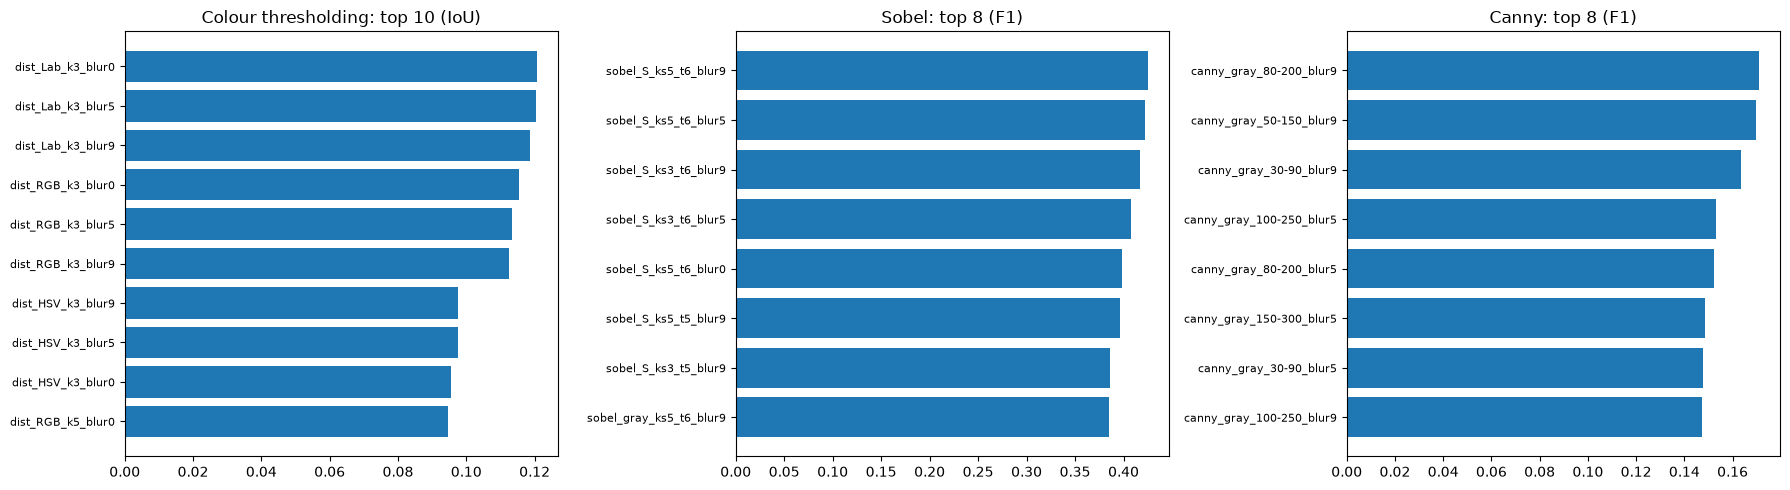

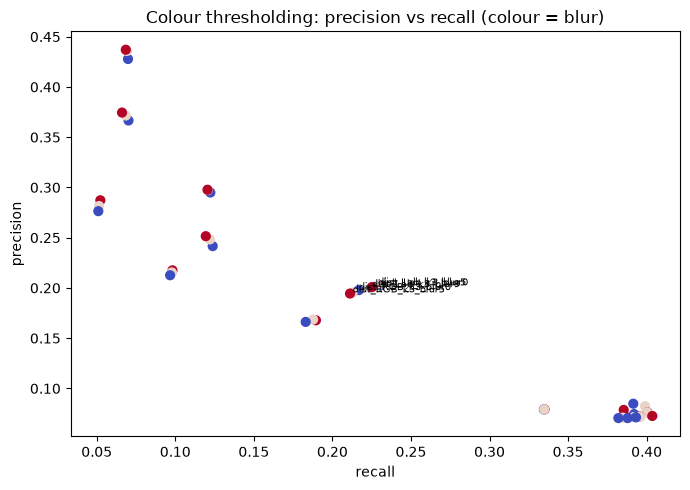

In [13]:
print("=== Colour thresholding (top 10 by IoU) ===")
print(color_res.head(10)[["setting", "precision", "recall", "f1", "iou", "box_recall", "mask_share"]].to_string(index=False))
print("\n=== Sobel (top 5 by F1) ===")
sobel_res = edge_res[edge_res.method == "sobel"].reset_index(drop=True)
print(sobel_res.head(5)[["setting", "edge_precision", "box_recall", "f1", "density_ratio"]].to_string(index=False))
print("\n=== Canny (top 5 by F1) ===")
canny_res = edge_res[edge_res.method == "canny"].reset_index(drop=True)
print(canny_res.head(5)[["setting", "edge_precision", "box_recall", "f1", "density_ratio"]].to_string(index=False))

print("\n--- Effect of the pre-blur (mean over all settings) ---")
print(color_res.groupby("blur")[["f1", "iou", "box_recall"]].mean().round(3).to_string())
print(edge_res.groupby(["method", "blur"])[["edge_precision", "box_recall", "f1"]].mean().round(3).to_string())
print("\n--- Effect of the colour space (best IoU per method / channel) ---")
print(color_res.groupby(["method", "channel"])["iou"].max().sort_values(ascending=False).round(3).to_string())

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
top = color_res.head(10)[::-1]
axes[0].barh(top.setting, top.iou); axes[0].set_title("Colour thresholding: top 10 (IoU)")
top = sobel_res.head(8)[::-1]
axes[1].barh(top.setting, top.f1); axes[1].set_title("Sobel: top 8 (F1)")
top = canny_res.head(8)[::-1]
axes[2].barh(top.setting, top.f1); axes[2].set_title("Canny: top 8 (F1)")
for ax in axes:
    ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.savefig(OUT_DIR / "04_setting_comparison.png", dpi=120)
plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(color_res.recall, color_res.precision, c=color_res.blur, cmap="coolwarm", s=40)
for r in color_res.head(5).itertuples():
    ax.annotate(r.setting, (r.recall, r.precision), fontsize=7)
ax.set(xlabel="recall", ylabel="precision", title="Colour thresholding: precision vs recall (colour = blur)")
plt.tight_layout()
plt.savefig(OUT_DIR / "04_precision_recall.png", dpi=120)
plt.show()

## 6. Best settings

In [14]:
def cfg_from_row(row, kind):
    if kind == "color":
        return dict(method=row.method, channel=row.channel, k=None if pd.isna(row.k) else int(row.k), blur=int(row.blur))
    if row.method == "canny":
        return dict(method="canny", channel=row.channel, blur=int(row.blur), lo=int(row.lo), hi=int(row.hi))
    return dict(method="sobel", channel=row.channel, blur=int(row.blur), ksize=int(row.ksize), t=int(row.t))


best_color = cfg_from_row(color_res.iloc[0], "color")
best_sobel = cfg_from_row(sobel_res.iloc[0], "edge")
best_canny = cfg_from_row(canny_res.iloc[0], "edge")

best = dict(split_used=SPLIT, n_images=len(samples),
            colour_threshold=dict(config=best_color, **color_res.iloc[0][["precision", "recall", "f1", "iou", "box_recall"]].to_dict()),
            sobel=dict(config=best_sobel, **sobel_res.iloc[0][["edge_precision", "box_recall", "f1", "density_ratio"]].to_dict()),
            canny=dict(config=best_canny, **canny_res.iloc[0][["edge_precision", "box_recall", "f1", "density_ratio"]].to_dict()),
            colour_space_ranking_centred=color_table["channel"].tolist())
(OUT_DIR / "best_settings.json").write_text(json.dumps(best, indent=2, default=float))
print(json.dumps(best, indent=2, default=float))

{
  "split_used": "val",
  "n_images": 150,
  "colour_threshold": {
    "config": {
      "method": "dist",
      "channel": "Lab",
      "k": 3,
      "blur": 0
    },
    "precision": 0.2025,
    "recall": 0.2303,
    "f1": 0.2155,
    "iou": 0.1208,
    "box_recall": 0.3645
  },
  "sobel": {
    "config": {
      "method": "sobel",
      "channel": "S",
      "blur": 9,
      "ksize": 5,
      "t": 6
    },
    "edge_precision": 0.3262,
    "box_recall": 0.6121,
    "f1": 0.4256,
    "density_ratio": 7.2403
  },
  "canny": {
    "config": {
      "method": "canny",
      "channel": "gray",
      "blur": 9,
      "lo": 80,
      "hi": 200
    },
    "edge_precision": 0.0977,
    "box_recall": 0.6869,
    "f1": 0.1711,
    "density_ratio": 1.5626
  },
  "colour_space_ranking_centred": [
    "V",
    "B",
    "G",
    "L",
    "R",
    "b",
    "H",
    "a",
    "S"
  ]
}


## 7. Visual results with the best settings

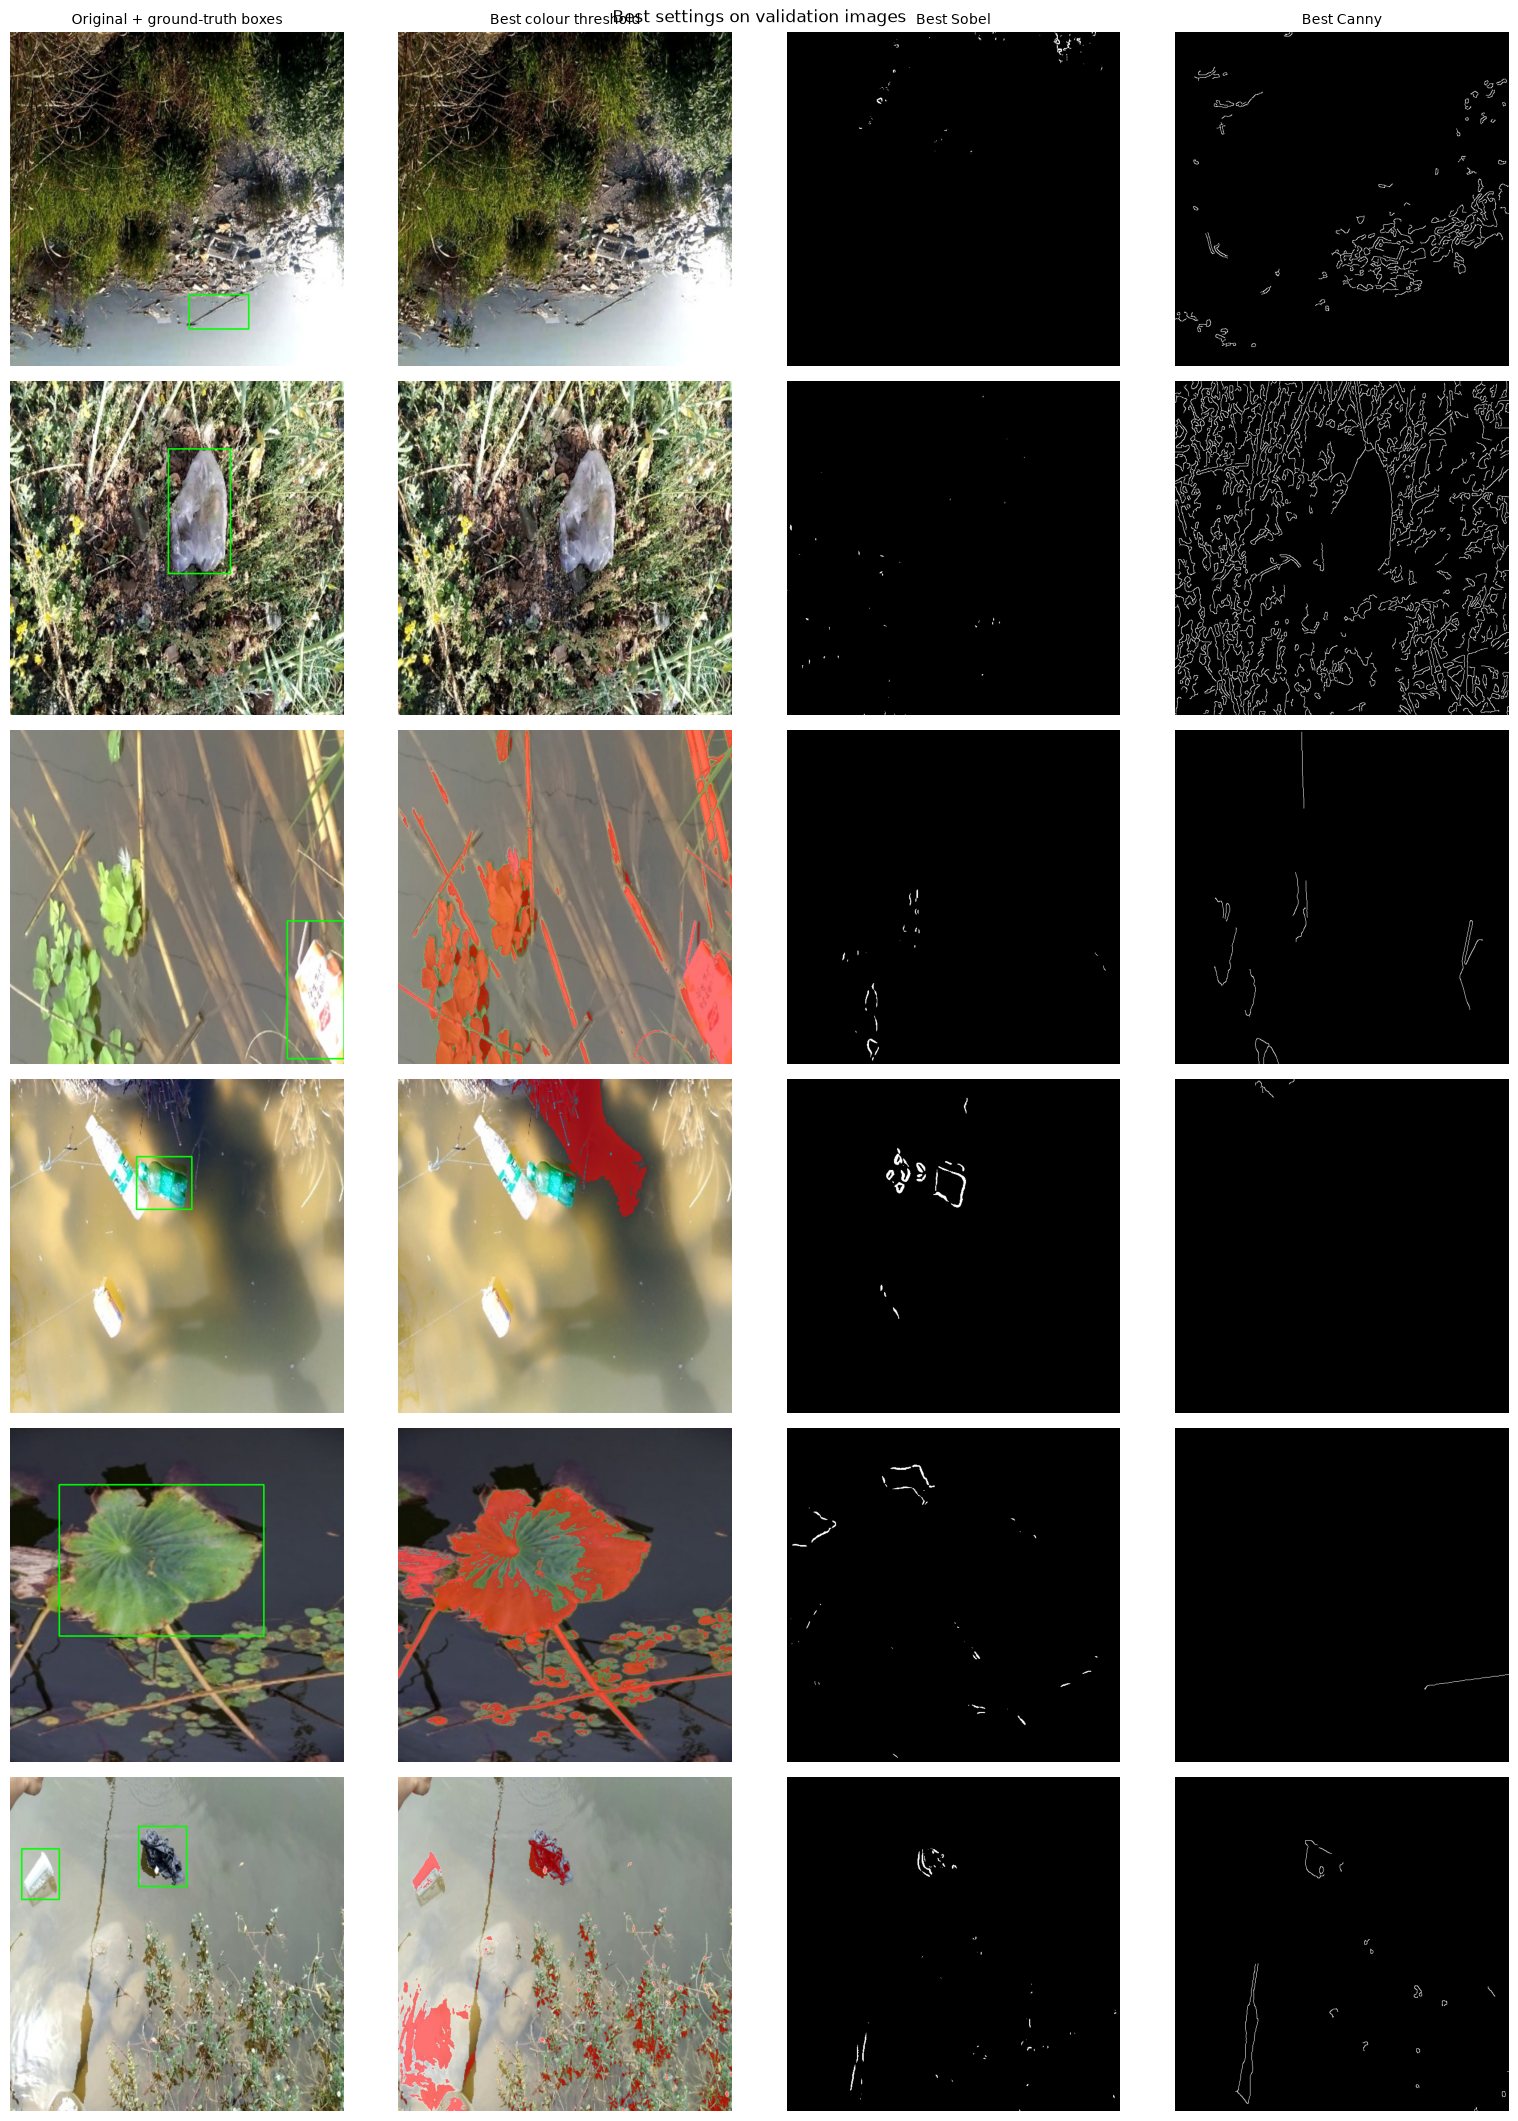

In [15]:
def overlay(img, mask, color=(0, 0, 255), alpha=0.55):
    out = img.copy()
    out[mask] = (out[mask] * (1 - alpha) + np.array(color) * alpha).astype(np.uint8)
    return out


def draw_gt(img, boxes):
    out = img.copy()
    for x0, y0, x1, y1 in boxes:
        cv2.rectangle(out, (x0, y0), (x1, y1), (0, 255, 0), 2)
    return out


def run_all(s):
    cm = color_pred(best_color, prep(s["img"], best_color["blur"], s["valid"]), s["valid"])
    so = edge_pred(best_sobel, prep(s["img"], best_sobel["blur"], s["valid"]), s["inner"])
    ca = edge_pred(best_canny, prep(s["img"], best_canny["blur"], s["valid"]), s["inner"])
    return cm, so, ca


def crop(img, s):
    x, y, w, h = cv2.boundingRect(s["valid"].astype(np.uint8))      # show only the real image, without padding
    return img[y:y + h, x:x + w]


def show_rows(chosen, title, fname, extra_titles=None):
    fig, axes = plt.subplots(len(chosen), 4, figsize=(16, 3.6 * len(chosen)))
    axes = np.atleast_2d(axes)
    for r, s in enumerate(chosen):
        cm, so, ca = run_all(s)
        panels = [draw_gt(s["img"], s["boxes"]), overlay(s["img"], cm),
                  cv2.cvtColor((so * 255).astype(np.uint8), cv2.COLOR_GRAY2BGR),
                  cv2.cvtColor((ca * 255).astype(np.uint8), cv2.COLOR_GRAY2BGR)]
        names = ["Original + ground-truth boxes", "Best colour threshold", "Best Sobel", "Best Canny"]
        for c, (pn, tt) in enumerate(zip(panels, names)):
            axes[r, c].imshow(cv2.cvtColor(crop(pn, s), cv2.COLOR_BGR2RGB))
            axes[r, c].axis("off")
            axes[r, c].set_title(tt if r == 0 else "", fontsize=10)
        axes[r, 0].set_ylabel(s["name"])
        if extra_titles:
            axes[r, 1].set_title(extra_titles[r], fontsize=9)
    plt.suptitle(title)
    plt.tight_layout()
    plt.savefig(OUT_DIR / fname, dpi=110)
    plt.show()


with_boxes = [s for s in samples if s["boxes"]]
vis_idx = np.linspace(0, len(with_boxes) - 1, min(N_VIS, len(with_boxes))).astype(int)
show_rows([with_boxes[i] for i in vis_idx], "Best settings on validation images", "05_best_settings_examples.png")

for i in vis_idx:                                                  # also store every result as a separate image
    s = with_boxes[i]
    cm, so, ca = run_all(s)
    stem = Path(s["name"]).stem
    cv_write(OUT_DIR / "visuals" / f"{stem}_original_gt.png", draw_gt(s["img"], s["boxes"]))
    cv_write(OUT_DIR / "visuals" / f"{stem}_colour_overlay.png", overlay(s["img"], cm))
    cv_write(OUT_DIR / "visuals" / f"{stem}_sobel.png", (so * 255).astype(np.uint8))
    cv_write(OUT_DIR / "visuals" / f"{stem}_canny.png", (ca * 255).astype(np.uint8))

### Failure cases
The images where the best colour threshold works worst. These are useful for the *limitations* part of the report (waste with a colour similar to the water, reflections, shadows ...).

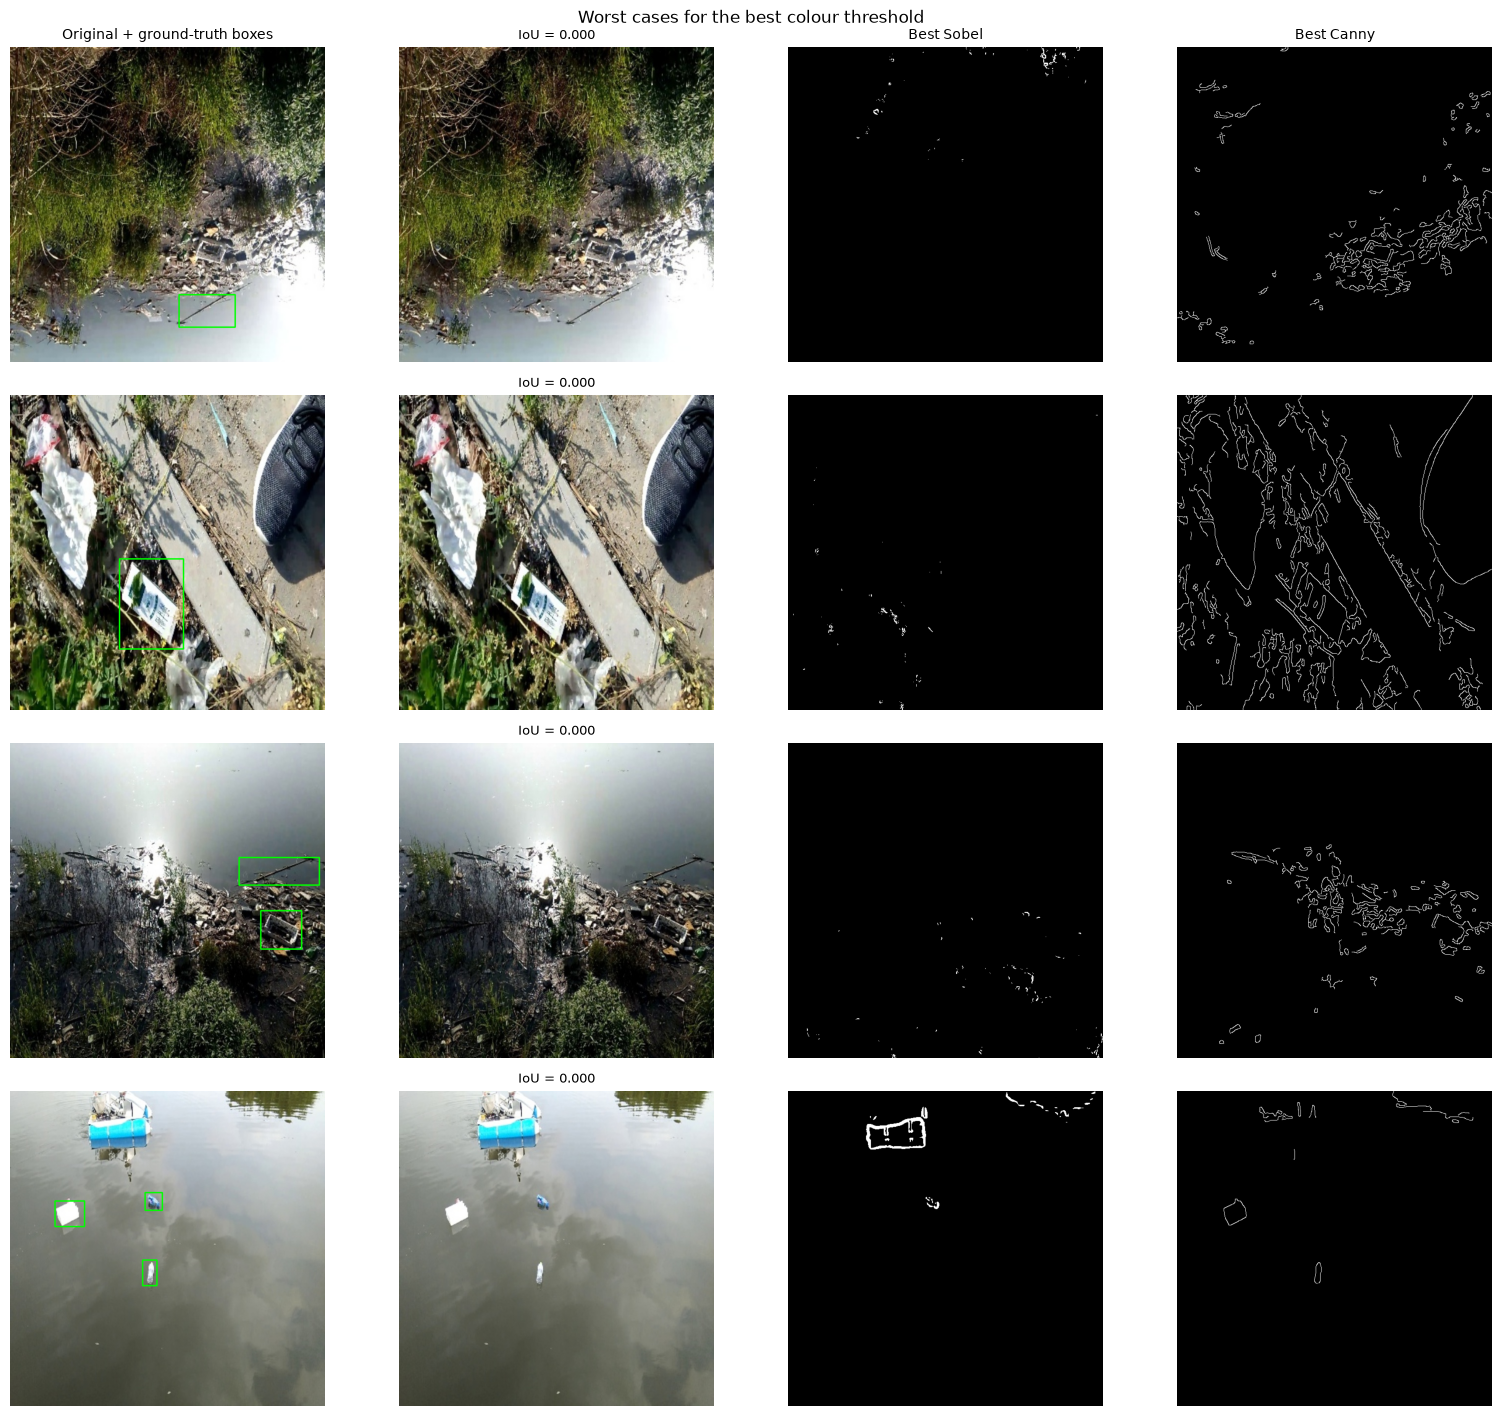

In [16]:
ious = np.array(color_acc[color_name(best_color)]["ious"], dtype=float)
order = [i for i in np.argsort(np.nan_to_num(ious, nan=9)) if not np.isnan(ious[i])][:4]
if order:
    show_rows([samples[i] for i in order], "Worst cases for the best colour threshold", "06_failure_cases.png",
              extra_titles=[f"IoU = {ious[i]:.3f}" for i in order])

## 8. Export for Person 3 (Morphology + Segmentation)


In [17]:
for s in samples:
    cm, so, ca = run_all(s)
    stem = Path(s["name"]).stem
    cv_write(OUT_DIR / "color_masks" / f"{stem}.png", (cm * 255).astype(np.uint8))
    cv_write(OUT_DIR / "sobel_edges" / f"{stem}.png", (so * 255).astype(np.uint8))
    cv_write(OUT_DIR / "canny_edges" / f"{stem}.png", (ca * 255).astype(np.uint8))

MODULE_HEAD = '''"""Stage 2 (Person 2): colour thresholding + edge detection with the best settings.

Usage:
    import stage2_color_edge as s2
    mask  = s2.color_mask(img_bgr)      # bool mask of floating-object candidates
    sobel = s2.sobel_edges(img_bgr)     # bool edge map
    canny = s2.canny_edges(img_bgr)     # bool edge map
img_bgr is a letterboxed image from rft_prepared (cv2.imread). The grey padding is ignored automatically.
"""
import cv2
import numpy as np

PAD_VALUE = __PAD__
PAD_TOL = __TOL__
'''

MODULE_TAIL = '''
COLOR_CFG = __COLOR__
SOBEL_CFG = __SOBEL__
CANNY_CFG = __CANNY__


def color_mask(img_bgr):
    valid, inner = make_valid(img_bgr)
    return color_pred(COLOR_CFG, prep(img_bgr, COLOR_CFG["blur"], valid), valid)


def sobel_edges(img_bgr):
    valid, inner = make_valid(img_bgr)
    return edge_pred(SOBEL_CFG, prep(img_bgr, SOBEL_CFG["blur"], valid), inner)


def canny_edges(img_bgr):
    valid, inner = make_valid(img_bgr)
    return edge_pred(CANNY_CFG, prep(img_bgr, CANNY_CFG["blur"], valid), inner)
'''

core = [content_bbox, make_valid, water_ref, prep, dist_map, robust_thr, otsu_minority, color_pred, edge_pred]
module_text = (MODULE_HEAD.replace("__PAD__", str(PAD_VALUE)).replace("__TOL__", str(PAD_TOL)) + "\n\n"
               + "\n\n".join(inspect.getsource(f).rstrip() + "\n" for f in core)
               + MODULE_TAIL.replace("__COLOR__", repr(best_color)).replace("__SOBEL__", repr(best_sobel)).replace("__CANNY__", repr(best_canny)))
(OUT_DIR / "stage2_color_edge.py").write_text(module_text)

# sanity check: the exported module must give exactly the same result as the notebook
import importlib.util
spec = importlib.util.spec_from_file_location("stage2_color_edge", OUT_DIR / "stage2_color_edge.py")
s2 = importlib.util.module_from_spec(spec)
spec.loader.exec_module(s2)
t = samples[0]
cm, so, ca = run_all(t)
assert np.array_equal(s2.color_mask(t["img"]), cm) and np.array_equal(s2.sobel_edges(t["img"]), so) and np.array_equal(s2.canny_edges(t["img"]), ca)
print("Exported module matches the notebook output.")

readme = f'''Person 2 hand-off (colour analysis + edge detection)
- stage2_color_edge.py          : import this in Person 3's code (color_mask / sobel_edges / canny_edges)
- best_settings.json            : best colour-threshold, Sobel and Canny settings (tuned on the {SPLIT} split)
- 01_*                          : colour-space analysis (RGB / HSV / Lab)
- 02_colour_threshold_results.csv, 03_edge_detection_results.csv : all compared settings
- 04_*, 05_*, 06_*              : comparison charts, visual examples, failure cases
- color_masks/ sobel_edges/ canny_edges/ : output images for the {len(samples)} {SPLIT} images (255 = detected)
- visuals/                      : separate images of the examples
Note: the images contain grey letterbox padding; it is excluded in every step.
'''
(OUT_DIR / "README.txt").write_text(readme)
zip_path = shutil.make_archive(str(OUT_DIR), "zip", OUT_DIR)
print("Hand-off ready:", Path(zip_path).resolve())

Exported module matches the notebook output.
Hand-off ready: D:\person2_output.zip
